<a href="https://colab.research.google.com/github/Laot-203/Ast-332/blob/main/Semana7/Semana_7_Photoz_RandomForests.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Random Forests and Photo-zs

En este notebook, se usa el algoritmo de random forest para estimar redshifts fotométricos a partir de observaciones de galaxias en 6 filtros diferentes  (u, g, r, i, z, y).

Basado en Machine learning for physics and Astronomy, Viviana Acquaviva (2023)

Trataremos de reproducir los resultados de [Zhou et. al. 2019](https://academic.oup.com/mnras/article/488/4/4565/5538813)

In [1]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_colwidth', 100)


font = {'size'   : 16}
matplotlib.rc('font', **font)
matplotlib.rc('xtick', labelsize=14)
matplotlib.rc('ytick', labelsize=14)
matplotlib.rcParams.update({'figure.autolayout': False})
matplotlib.rcParams['figure.dpi'] = 300

In [2]:
from sklearn import metrics
from sklearn.model_selection import cross_validate, KFold, cross_val_predict, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor

In [3]:
#!pip install astropy
import astropy

from astropy.io import fits


#### Importamos los datos

Leemos el archivo fits y lo leemos usando pandas

In [5]:
with fits.open('DEEP2_uniq_Terapix_Subaru_v1.fits') as data:
  arr = np.array(data[1].data)
  arr = arr.byteswap().view(arr.dtype.newbyteorder())
  df = pd.DataFrame(arr)
    #https://numpy.org/doc/2.1/user/byteswapping.html

In [6]:
df.columns

Index(['objno_deep2', 'ra_deep2', 'dec_deep2', 'magb', 'magr', 'magi', 'pgal',
       'sfd_ebv', 'class', 'subclass', 'objname', 'maskname', 'slitname',
       'date', 'mjd', 'z_raw', 'zhelio', 'z_err', 'rchi2', 'dof', 'vdisp',
       'vdisp_err', 'zquality', 'egsflags', 'comment', 'm_b', 'ub_0',
       'ra_cfhtls', 'dec_cfhtls', 'u', 'g', 'r', 'i', 'i2', 'z', 'uerr',
       'gerr', 'rerr', 'ierr', 'i2err', 'zerr', 'u_apercor', 'g_apercor',
       'r_apercor', 'i_apercor', 'i2_apercor', 'z_apercor', 'uerr_aper',
       'gerr_aper', 'rerr_aper', 'ierr_aper', 'i2err_aper', 'zerr_aper',
       'uerr_apercor', 'gerr_apercor', 'rerr_apercor', 'ierr_apercor',
       'i2err_apercor', 'zerr_apercor', 'r_radius_arcsec', 'u(sexflag)',
       'g(sexflag)', 'r(sexflag)', 'i(sexflag)', 'i2(sexflag)', 'z(sexflag)',
       'flag_cfhtls', 'cfhtls_source', 'ra_subaru', 'dec_subaru', 'y', 'yerr',
       'y_apercor', 'yerr_aper', 'yerr_apercor', 'y(sexflag)',
       'y_radius_arcsec', 'subaru_source'],
 

In [7]:
df.head()

,objno_deep2,ra_deep2,dec_deep2,magb,magr,magi,pgal,sfd_ebv,class,subclass,objname,maskname,slitname,date,mjd,z_raw,zhelio,z_err,rchi2,dof,vdisp,vdisp_err,zquality,egsflags,comment,m_b,ub_0,ra_cfhtls,dec_cfhtls,u,g,r,i,i2,z,uerr,gerr,rerr,ierr,i2err,zerr,u_apercor,g_apercor,r_apercor,i_apercor,i2_apercor,z_apercor,uerr_aper,gerr_aper,rerr_aper,ierr_aper,i2err_aper,zerr_aper,uerr_apercor,gerr_apercor,rerr_apercor,ierr_apercor,i2err_apercor,zerr_apercor,r_radius_arcsec,u(sexflag),g(sexflag),r(sexflag),i(sexflag),i2(sexflag),z(sexflag),flag_cfhtls,cfhtls_source,ra_subaru,dec_subaru,y,yerr,y_apercor,yerr_aper,yerr_apercor,y(sexflag),y_radius_arcsec,subaru_source
0,11001673,213.868704,51.956445,23.487745,23.143082,22.582092,1.000000,0.010943,b'',b'',b'11001673',b'1101',b'000',b'2003-05-06',52765.457031,1.115297,1.115261,999.900024,0.630934,57.0,999.900024,999.900024,2,16777216,"b'bext, bcol, possible OII'",-999.000000,-999.0000,213.868620,51.956434,23.529039,23.393115,23.148170,22.854212,-99.0,22.162377,0.0678,0.0400,0.0382,0.0678,-99.0,0.0623,23.543491,23.430495,23.100311,22.768970,-99.0,22.223810,0.0542,0.0323,0.0279,0.0466,-99.0,0.0536,0.039631,0.041359,0.039777,0.046863,-99.0,0.043833,0.581804,3,3,3,3,-99,3,0,1,213.868626,51.956443,21.869627,0.060918,21.926356,0.041955,0.141778,3.0,0.656514,1
1,11001699,213.810471,51.942316,22.067692,20.034674,19.545080,3.000000,0.011014,b'GALAXY',b'',b'11001699',b'1100',b'7',b'2003-05-03',52762.441406,0.290641,0.290608,0.000043,1.178153,5901.0,166.334991,49.481255,4,16777216,b'',-19.228701,1.1295,213.810138,51.942348,30.123756,28.298480,18.540350,99.000000,-99.0,99.000000,0.0000,0.0000,0.0014,99.0000,-99.0,99.0000,30.848978,28.989668,19.027422,99.000000,-99.0,99.000000,0.0000,0.0000,0.0028,99.0000,-99.0,99.0000,0.029567,0.030353,0.027558,99.000000,-99.0,99.000000,0.824625,19,19,19,3,-99,3,244,1,213.810455,51.942321,18.757229,0.005813,18.811085,0.004386,0.050987,3.0,0.744269,1
2,11001770,213.848431,51.948876,24.144438,24.103180,24.020006,3.000000,0.010856,b'GALAXY',b'',b'11001770',b'1101',b'003',b'2003-05-06',52765.457031,0.605779,0.605744,-5.000000,1.047260,5318.0,184.860001,195.000000,1,16777216,b'',-999.000000,-999.0000,213.848409,51.948865,24.294289,24.399293,24.413366,23.398456,-99.0,24.157690,0.1646,0.1383,0.2306,0.1867,-99.0,0.4558,24.324670,24.273606,24.150319,23.446252,-99.0,23.574236,0.1146,0.0870,0.1242,0.1309,-99.0,0.1793,0.111127,0.130134,0.123620,0.117813,-99.0,0.101059,0.728119,0,0,0,0,-99,0,0,1,-99.000000,-99.000000,-99.000000,-99.000000,-99.000000,-99.000000,-99.000000,-99.0,-99.000000,-99
3,11001800,213.831758,51.952548,25.336836,23.508480,23.081087,0.509809,0.010823,b'GALAXY',b'',b'11001800',b'1100',b'004',b'2003-05-03',52762.441406,1.306830,1.306796,-5.000000,1.014062,5788.0,0.000000,0.000000,1,16777216,b'',-999.000000,-999.0000,213.831785,51.952539,26.363821,24.530998,23.559140,23.065110,-99.0,22.737333,0.9609,0.1344,0.0648,0.0997,-99.0,0.1110,99.000000,24.804309,23.636544,23.009222,-99.0,22.689591,99.0000,0.1077,0.0426,0.0568,-99.0,0.0661,99.000000,0.046521,0.041142,0.054297,-99.0,0.053818,0.549061,0,0,0,0,-99,0,0,1,213.831766,51.952544,22.404269,0.088970,22.535600,0.053497,0.094733,0.0,0.455820,1
4,11001860,213.832550,51.954174,24.382738,23.401484,22.572845,3.000000,0.010827,b'GALAXY',b'',b'11001860',b'1101',b'10',b'2003-05-06',52765.457031,0.957705,0.957669,0.000099,1.039979,5952.0,109.394997,17.208755,4,16777216,b'',-20.083200,0.7524,213.832540,51.954167,24.571406,24.023086,23.493832,22.691404,-99.0,22.387428,0.1924,0.0874,0.0651,0.0715,-99.0,0.0850,24.362068,24.136913,23.490342,22.777181,-99.0,22.319676,0.1002,0.0615,0.0420,0.0473,-99.0,0.0508,0.050326,0.053198,0.052364,0.058492,-99.0,0.053587,0.595684,0,0,0,0,-99,0,0,1,213.832574,51.954175,22.242717,0.070760,22.100980,0.033256,0.073067,0.0,0.442022,1


In [8]:
df.shape

(23822, 78)

Seleccione las columnas que contienen el brillo de las galaxias en los 6 filtros de interés, 'u,g,r,i,z,y' (con sufijo 'apercor') como las características y el redshift (espectroscópico) como la variable a predecir (`zhelio`)

In [9]:
features = df[['u_apercor', 'g_apercor', 'r_apercor', 'i_apercor', 'z_apercor', 'y_apercor']]

In [10]:
target = df['zhelio']

### Ahora empezaremos a implementar nuestro modelo de Random Forest

Figura 5 del paper

 ![Performance of photometric redshift reconstruction](https://oup.silverchair-cdn.com/oup/backfile/Content_public/Journal/mnras/488/4/10.1093_mnras_stz1866/1/stz1866fig5.jpeg?Expires=1764255560&Signature=YsogBmQvQ0CkbNXBEimFc23Rt9Slq~Q5qJGdV1YfvS3w-Z3IEJvD7FrYcOoSm6U0xY-gU~5JqYe2A7wjaHjQ~GAPOIZP8Kod-zh~1sxPBUDM3aj4kio313nsCcC-zCJRDd1OEvPncis9N7puYcPeqj2R3rSNaGk4QJCOBtGhE5-NLbwFbQFalDhy7dELFeMm4uZQxaCwNeJF1NsQBETobU-LK13KulZ51tMrLF1HiDEjQetQBvccYAG6sC2fTWrNNtv9lSl9PEaac9qHSycwfyDc8GeHPFyh~DmL7KSQM3V1PEEkjG6-RYrwZaXYBorj5PkR9ZLJQzoNqRxn4Gl7rg__&Key-Pair-Id=APKAIE5G5CRDK6RD3PGA)

En la figura, $\sigma_{NMAD}$ es la [normalized median absolute deviation de los residuos](https://en.wikipedia.org/wiki/Median_absolute_deviation), definida como $\sigma_{NMAD}=1.48\cdot MAD$, donde $MAD = \text{median}(\frac{|\Delta z|}{(1 + zspec)})$, $\Delta z =z_{phot}-z_{spec}$  y $\eta$ es la fracción de outliers definido como los objetos que cumplen $|(\Delta z)| > 0.15\cdot(1+z_{spec})$



In [11]:
model = RandomForestRegressor()

In [12]:
model.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': None,
 'max_features': 1.0,
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': None,
 'verbose': 0,
 'warm_start': False}

Empezaremos estableciendo un benchmark

Implemente el modelo de random forest definido arriba en esquema de validación cruzada KFold, reporte la métrica para entrenamiento y prueba. Recordemos que la métrica por defecto es $R^2$

In [13]:
%%time
scores = cross_validate(model, features, target, cv = KFold(), return_train_score = True)

CPU times: user 1min 53s, sys: 494 ms, total: 1min 53s
Wall time: 1min 55s


In [14]:
scores

{'fit_time': array([22.91441941, 22.03097153, 21.07984161, 22.35976362, 22.81922197]),
 'score_time': array([0.17818594, 0.22007966, 0.18271875, 0.17870617, 0.18200541]),
 'test_score': array([0.24490703, 0.34869433, 0.2593096 , 0.29801005, 0.28409417]),
 'train_score': array([0.87350697, 0.86869841, 0.87756517, 0.87808258, 0.88232992])}

Calcule el promedio y la desviación estándar de las métricas obtenidas.

In [19]:
print(scores['train_score'].mean())   #Promedio de datos de entrenamiento.
print(scores['test_score'].mean())    #Promedio de datos de prueba.

0.8760366074540153
0.28700303524816356


In [20]:
print(scores['train_score'].std())    #Desviación estandar de entrenamiento.
print(scores['test_score'].std())     #Desviación estandar de prueba.

0.00461251541515177
0.03598453023973173


**Qué puede decir de este resultado? Hay bias alto o varianza alta?**

**r:** Se puede observar que los promedios cambian drasticamente, ademas de un aumento notorio en la desviación estandar. Por lo que se puede concluir que es alto bias y alta varianza.

Puede comparar los valores reales con los predichos, generando las predicciones con `cross_val_predict`

In [21]:
ypred = cross_val_predict(model, features, target, cv = KFold())
#Exceptuamos return_train_score = True para que no nos muestre nada.

(0.0, 3.0)

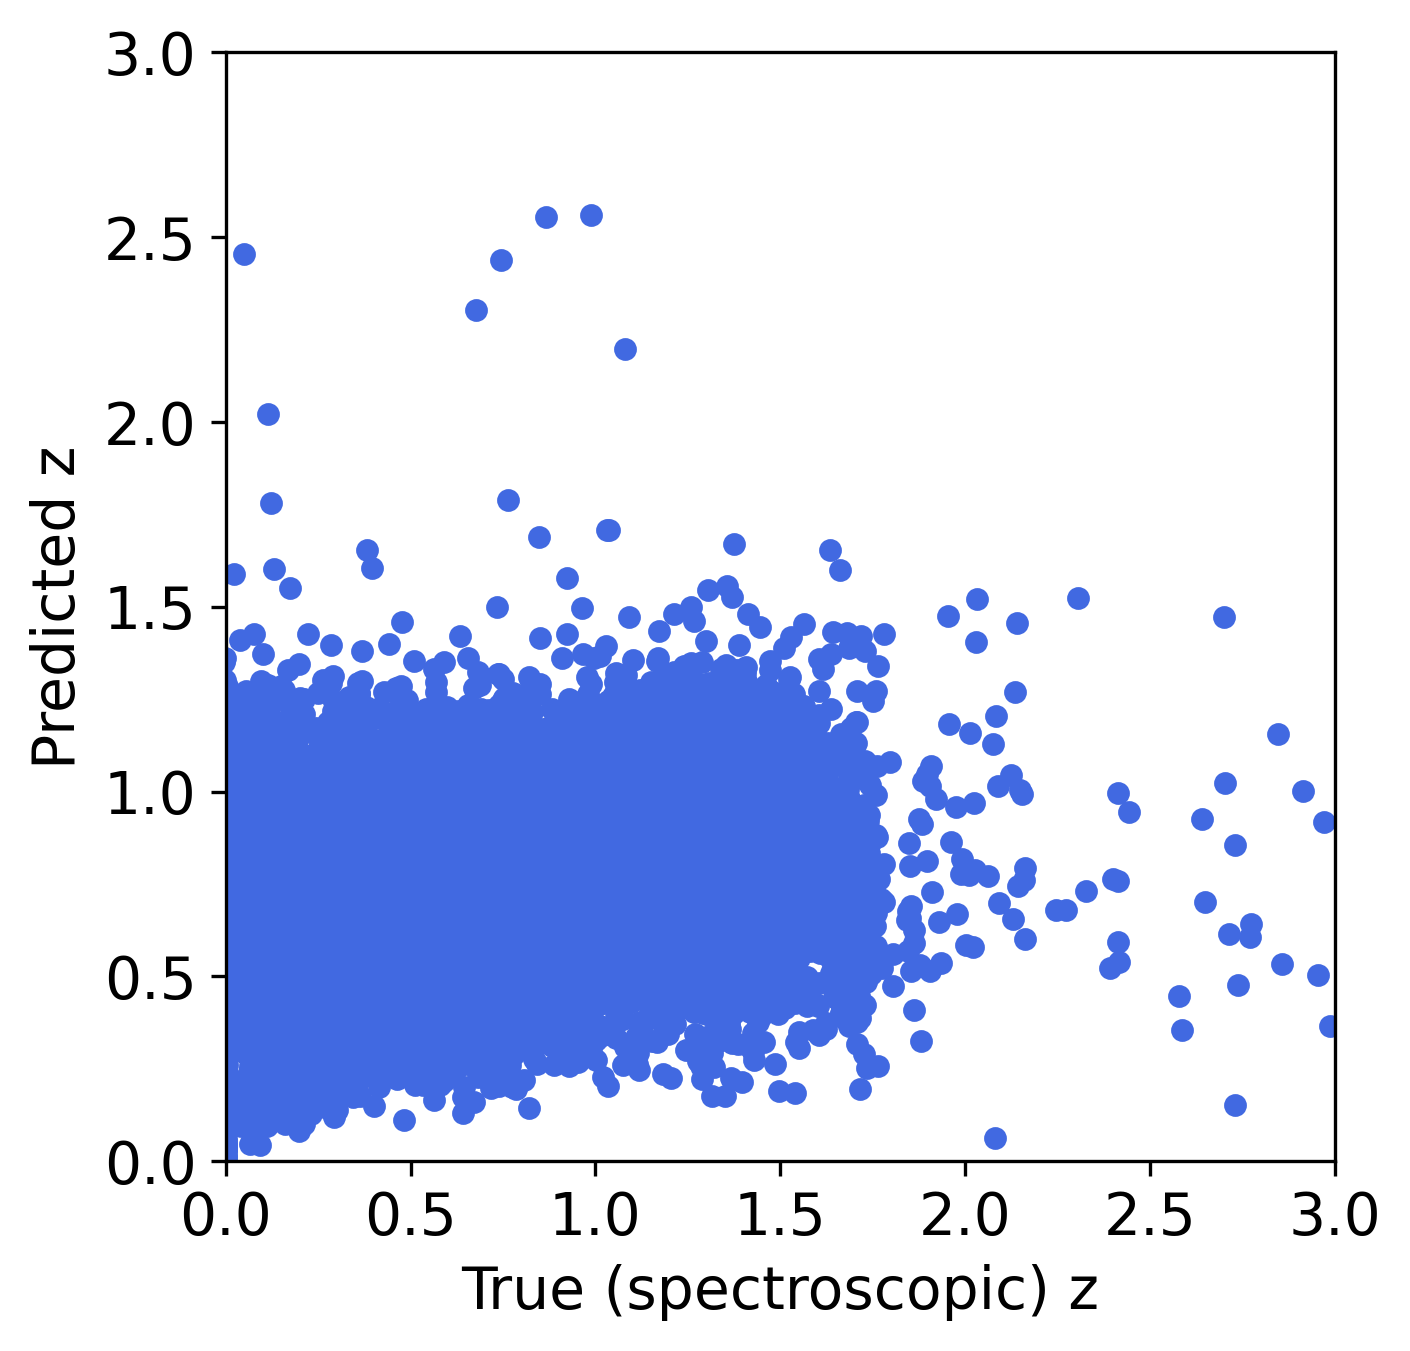

In [22]:
plt.scatter(target,ypred, s = 20, c = 'royalblue')
plt.xlabel('True (spectroscopic) z', fontsize=14)
plt.ylabel('Predicted z',fontsize=14)
plt.axis('square')
plt.xlim(0,3)
plt.ylim(0,3)

### Se parece al resultado del paper??

**r:** Tiene un aire a lo que buscamos :D pero no es parecido.

También es interesante observar la distribución de los valores predichos, para ver cómo siempre tienden a producir una distribución más estrecha.

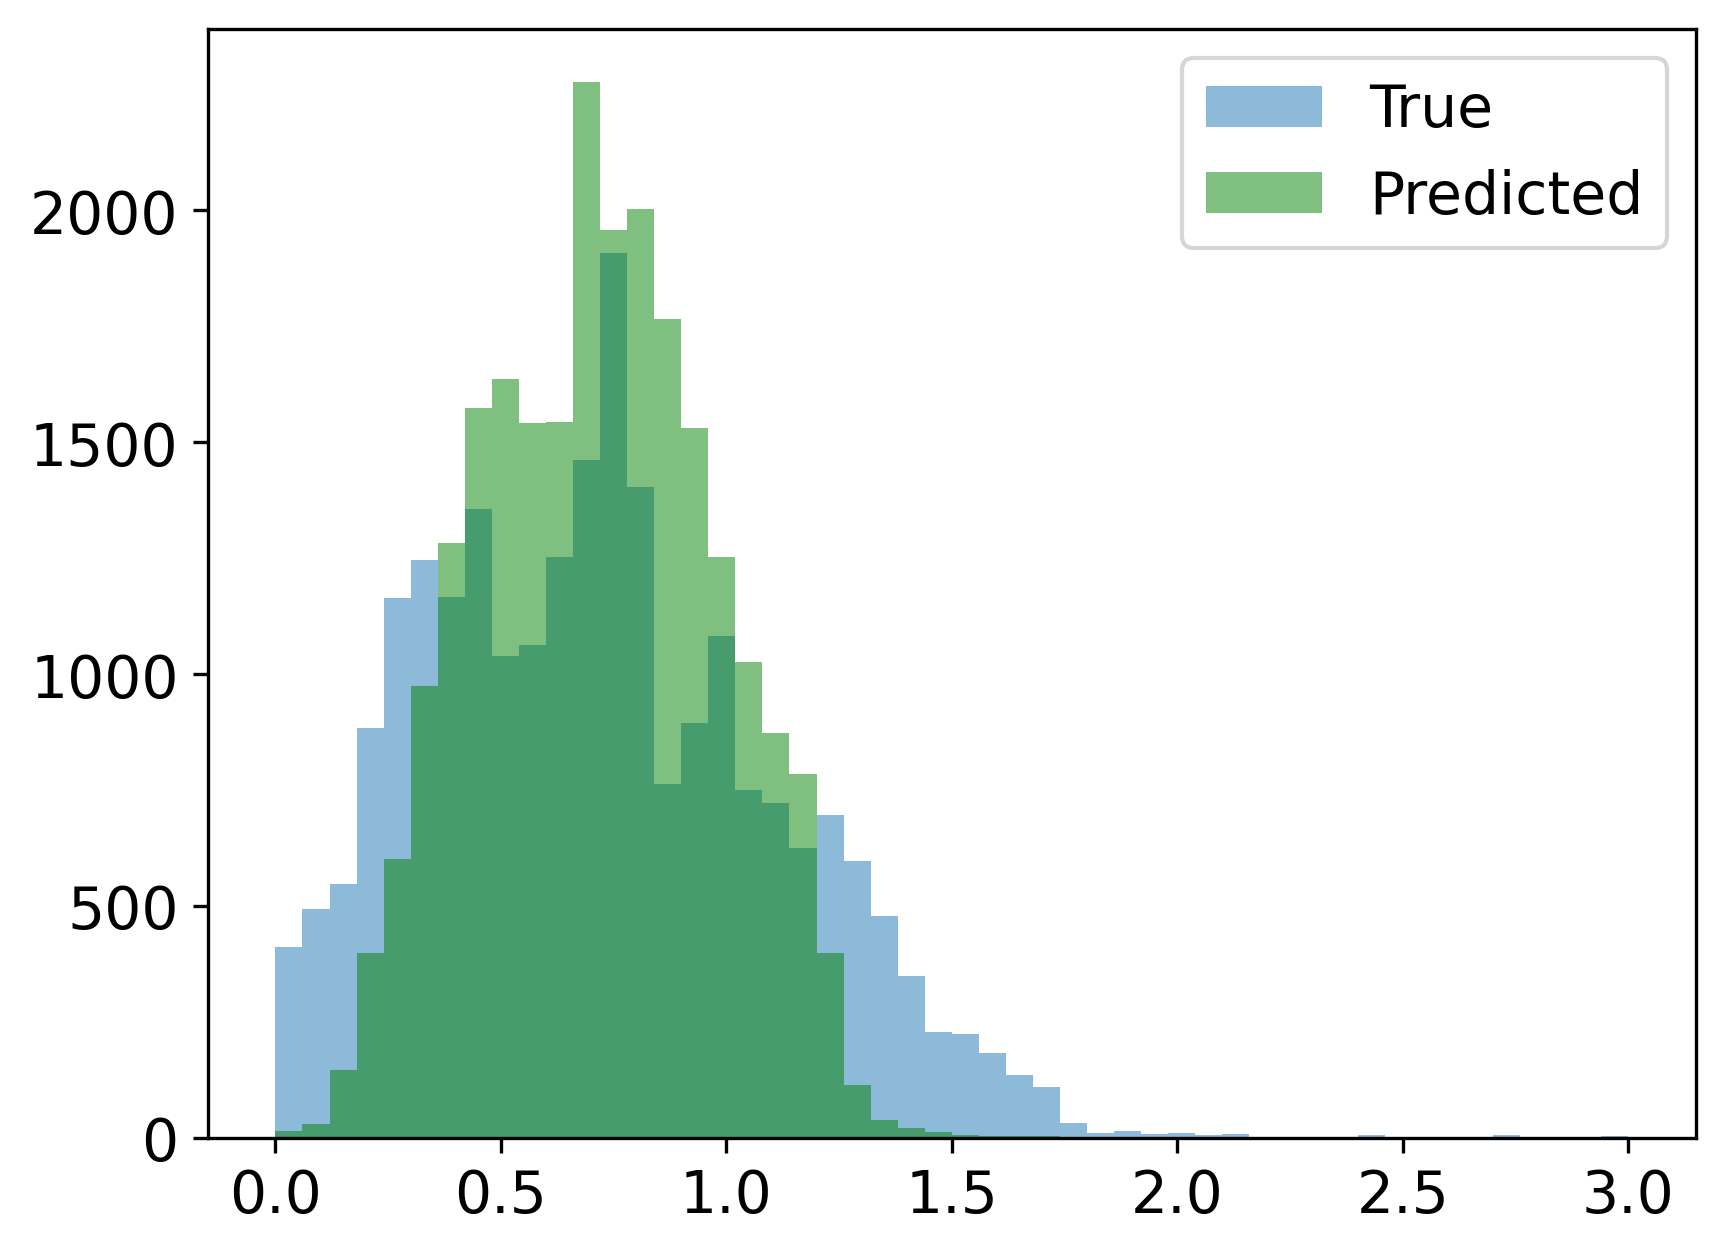

In [23]:
plt.hist(target,bins=50,density=False,alpha=0.5, range = (0,3), label = 'True');
plt.hist(ypred,bins=50,density=False,alpha=0.5, range = (0,3), color = 'g', label = 'Predicted');
plt.legend(fontsize=14);

Ahora calcule las métricas del paper, fracción de outliers $eta$ y $\sigma_{NMAD}$ y compare con los resultados del paper

In [33]:
dz_norm = (ypred - target) / (1 + target) #Calculamos eta
dz_norm.describe()

,zhelio
count,23822.000000
mean,0.039288
std,0.220288
min,-0.725150
25%,-0.043451
50%,0.002435
75%,0.062297
max,2.290843


In [37]:
eta = (dz_norm.abs() > 0.15).mean()
print(eta)
print(f'Comparación wide: {eta - 0.063:.3f}')
print(f'Comparación deep: {eta - 0.047:.3f}')

0.25850054571404585
Comparación wide: 0.196
Comparación deep: 0.212


y NMAD

In [41]:
sigma_nmad = 1.48 * dz_norm.abs().median()    #Calculamos sigma con la cte del paper 1.48
print(sigma_nmad)
print(f'Comparación wide: {sigma_nmad - 0.039:.3f}')
print(f'Comparación deep: {sigma_nmad - 0.018:.3f}')

0.07545512082387852
Comparación wide: 0.036
Comparación deep: 0.057


### Optimicemos los hiperparámetros del modelo

Seleccionemos un subsample de los datos para que se reduzcan los tiempos computacionales

In [42]:
np.random.seed(20)
sel = np.random.choice(range(len(ypred)), 5000, replace = False) #sample sin reemplazo

In [43]:
len(np.unique(sel))

5000

Y creamos nuestro nuevo dataset más pequeño

In [44]:
seld = features.loc[sel,:]
selt = target[sel]

Chequeemos que la performance del modelo usando todo el set de datos es similar a los obtenidos con nuestro set de datos menor, lo que significaria que el cambio en el tamaño del set no afectará el proceso de optimización

In [45]:
littlescores = cross_validate(model,seld,selt, cv = KFold(n_splits=5, shuffle=True, random_state=10), return_train_score=True)

In [46]:
littlescores['test_score'].mean(), littlescores['train_score'].mean()

(np.float64(0.27762715338769406), np.float64(0.8763722031531694))

### Estamos listos para optimizar hiperparámetros...cuáles escogemos?


#### Parámetros de árbol

- El número mínimo de instancias en un nodo hoja

- El número mínimo de instancias requerido en un nodo de división

- La profundidad máxima del árbol

- El criterio elegido para decidir si una división "vale la pena", expresado en términos de ganancia de información

#### Parámetros de randomización



- El número de $k < n$ características que se utilizan para construir los árboles

- El resampling (bootstrap) del conjunto de datos (Verdadero o Falso)

#### Parámetros del bosque

El número de árboles en el bosque (n_estimators) se puede ajustar, con el entendimiento general de que más árboles son mejores, pero en algún punto el rendimiento se estabiliza, por lo que se puede encontrar el equilibrio entre tener más árboles y un menor tiempo de ejecución.

Podemos visualizarlos así

In [47]:
model.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': None,
 'max_features': 1.0,
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': None,
 'verbose': 0,
 'warm_start': False}

Implemente `GridSearchCV` o `RandomizedGridSearch()` para los siguientes parámetros y compare los resultados del mejor modelo con los del paper

- min_impurity_decrease

- number of trees

- max_leaf_nodes

- min_samples_split

- max_features

In [49]:
%%time
#Toma algunos minutos
parameters = {'min_impurity_decrease':[0.1, 0.5, 0.0], \
              'max_features':[None,4,2], 'n_estimators':[50, 100, 200], 'min_samples_split': [10,20,100],
              'max_leaf_nodes':[None, 100, 200]}
model = GridSearchCV(RandomForestRegressor(), parameters, cv = KFold(), return_train_score = True)
model.fit(seld, selt)

CPU times: user 20min 33s, sys: 1.56 s, total: 20min 35s
Wall time: 20min 56s


GridSearchCV(cv=KFold(n_splits=5, random_state=None, shuffle=False),
             estimator=RandomForestRegressor(),
             param_grid={'max_features': [None, 4, 2],
                         'max_leaf_nodes': [None, 100, 200],
                         'min_impurity_decrease': [0.1, 0.5, 0.0],
                         'min_samples_split': [10, 20, 100],
                         'n_estimators': [50, 100, 200]},
             return_train_score=True)

Guardamos el resultado en un dataframe y buscamos el mejor modelo

In [50]:
scores = pd.DataFrame(model.cv_results_)
scoresCV = scores[['params','mean_test_score','std_test_score','mean_train_score']].sort_values(by = 'mean_test_score', \
                                                    ascending = False)


In [51]:
scoresCV

,params,mean_test_score,std_test_score,mean_train_score
100,"{'max_features': 4, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 1...",0.303584,0.020705,0.750201
102,"{'max_features': 4, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 2...",0.302484,0.023221,0.645952
104,"{'max_features': 4, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 2...",0.300953,0.017199,0.652570
101,"{'max_features': 4, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 1...",0.300206,0.018656,0.753340
182,"{'max_features': 2, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_split': 1...",0.300122,0.018819,0.726293
...,...,...,...,...
114,"{'max_features': 4, 'max_leaf_nodes': 100, 'min_impurity_decrease': 0.1, 'min_samples_split': 10...",-0.001562,0.001870,-0.000004
172,"{'max_features': 2, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.5, 'min_samples_split': 1...",-0.001569,0.001946,-0.000003
222,"{'max_features': 2, 'max_leaf_nodes': 200, 'min_impurity_decrease': 0.1, 'min_samples_split': 10...",-0.001575,0.001865,-0.000008
27,"{'max_features': None, 'max_leaf_nodes': 100, 'min_impurity_decrease': 0.1, 'min_samples_split':...",-0.001583,0.001880,-0.000004


### Mejoran los scores?

**r:** Si mejoran más con max_leaf_nodes=none, min_impurity_decrease=0.0 y max_features de 4 o 2. Esto dandonos 5 modelos a elegir estando muy empatados.

### Un poco de ingeniería de características

Miraremos otras columnas disponibles del set de datos (Tabla 6 del paper)

In [52]:
mags = df[['u_apercor', 'g_apercor', 'r_apercor', 'i_apercor', 'z_apercor','y_apercor','subaru_source','cfhtls_source','zquality']]



In [53]:
mags.head()

,u_apercor,g_apercor,r_apercor,i_apercor,z_apercor,y_apercor,subaru_source,cfhtls_source,zquality
0,23.543491,23.430495,23.100311,22.768970,22.223810,21.926356,1,1,2
1,30.848978,28.989668,19.027422,99.000000,99.000000,18.811085,1,1,4
2,24.324670,24.273606,24.150319,23.446252,23.574236,-99.000000,-99,1,1
3,99.000000,24.804309,23.636544,23.009222,22.689591,22.535600,1,1,1
4,24.362068,24.136913,23.490342,22.777181,22.319676,22.100980,1,1,4


In [54]:
mags.shape

(23822, 9)

In [55]:
#zquality - solo usa objetos con medición de redshift de buena calidad

mags = mags[mags['zquality'] >= 3]

mags.shape

(16857, 9)

In [56]:
#selecciona objetos con datos del catálogo cfhtls deep photometric data

mags = mags[mags['cfhtls_source'] == 0]

mags.shape

(10671, 9)

Las mediciones no disponibles están marcadas por -99 o 99 (mientras que los valores típicos están alrededor de 20-25). También eliminamos los datos con mediciones faltantes.

In [57]:
mags = mags[mags > -10].dropna()

In [58]:
mags.shape

(6371, 9)

In [59]:
mags = mags[mags < 90].dropna()

In [60]:
mags.shape

(6307, 9)

Tenemos un dataset con las 6 features originales y 6307 objetos

In [61]:
sel_features = mags[['u_apercor', 'g_apercor', 'r_apercor', 'i_apercor', 'z_apercor','y_apercor']]
sel_features.head()

,u_apercor,g_apercor,r_apercor,i_apercor,z_apercor,y_apercor
1251,24.244393,23.979583,23.522136,22.911041,22.525773,22.329098
1253,24.489104,23.916151,22.923651,21.873752,21.306495,21.251440
1261,24.873959,22.973893,21.465850,20.788420,20.462283,20.413696
1271,24.529042,24.338631,23.891189,23.206102,22.989344,23.112382
1272,23.641180,23.387447,22.975301,22.235199,21.809658,21.559483


Selección del vector de target

In [62]:
sel_target = target[sel_features.index]

**Vuelva a correr el modelo benchmark con estas nuevas características y compare con los resultados anteriores. Puede optimizar nuevamente los hiperparámetros para mejorar aún más el modelo. Compare los valores predichos con los valores reales y concluya respecto a los resultados con la nueva selección de datos.**

In [63]:
scores_new = cross_validate(RandomForestRegressor(), sel_features, sel_target, cv = KFold(), return_train_score = True)


In [64]:
print(scores_new['train_score'].mean())
print(scores_new['test_score'].mean())

0.9636318690320665
0.7447087839913044


In [68]:
ypred_new = cross_val_predict(RandomForestRegressor(), sel_features, sel_target, cv = KFold())
#Ahora calculamos los nuevos eta y sigma para comparar con el modelo del paper.

dz_norm_new = (ypred_new - sel_target) / (1 + sel_target)
eta_new = (dz_norm_new.abs() > 0.15).mean()
print(eta_new)

sigma_nmad_new = 1.48 * dz_norm_new.abs().median()
print(sigma_nmad_new)

0.05676232757253845
0.036958338016493245


### Conclusion: Cómo se compara nuestro modelo con el resultado del paper?

Revise la sección 7 del paper. Podemos mejorar nuestro modelo aún más? Implemente un nuevo modelo con la mejora identificada



**r:** El paper menciona que se obtuvo un mejor resultado con los colores y la magnitud i, en vez de solo las magnitudes:

In [69]:
colores = pd.DataFrame()
colores['u-g'] = sel_features['u_apercor'] - sel_features['g_apercor']
colores['g-r'] = sel_features['g_apercor'] - sel_features['r_apercor']
colores['r-i'] = sel_features['r_apercor'] - sel_features['i_apercor']
colores['i-z'] = sel_features['i_apercor'] - sel_features['z_apercor']
colores['z-y'] = sel_features['z_apercor'] - sel_features['y_apercor']
colores['i'] = sel_features['i_apercor']

colores.head()

,u-g,g-r,r-i,i-z,z-y,i
1251,0.264811,0.457447,0.611094,0.385268,0.196675,22.911041
1253,0.572953,0.992500,1.049899,0.567258,0.055055,21.873752
1261,1.900066,1.508042,0.677430,0.326138,0.048586,20.788420
1271,0.190411,0.447442,0.685087,0.216758,-0.123037,23.206102
1272,0.253733,0.412146,0.740102,0.425541,0.250175,22.235199


In [71]:
scores_colores = cross_validate(RandomForestRegressor(max_features = 4, min_samples_split = 10), colores, sel_target, cv = KFold(), return_train_score = True)
print(scores_colores['train_score'].mean())
print(scores_colores['test_score'].mean())
#Generamos un nuevo modelo con las mejoras encontradas.

0.93994563358253
0.8133075261652521


In [72]:
ypred_colores = cross_val_predict(RandomForestRegressor(max_features = 4, min_samples_split = 10), colores, sel_target, cv = KFold())
#Ahora calculamos los nuevos eta y sigma, y comparamos.

dz_norm_color = (ypred_colores - sel_target) / (1 + sel_target)
eta_color = (dz_norm_color.abs() > 0.15).mean()
print(eta_color)

sigma_nmad_color = 1.48 * dz_norm_color.abs().median()
print(sigma_nmad_color)

0.035991755192643096
0.017129524420340173


Con esto se alcanza los números del paper; un sigma 0.0171 vs 0.018 y un eta del 3.6% vs 4.7% llegando a la conclusión de que se logra reproducir la precisión del paper